# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 1. Modelos supervisados y métricas (Semana 12)

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Brazilian E-Commerce Public Dataset by Olist

Objetivo: construir un modelo base para anticipar entregas tardías a partir de datos de compras, productos, clientes, vendedores y pagos.

Las instrucciones de GitHub y entrega se encuentran en el documento técnico. Las secciones de carga y preparación se suministran resueltas; complete las cuatro actividades de modelado y evaluación.

## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [ ]:
import hashlib
import json
from pathlib import Path


import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)

In [ ]:

ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [ ]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [ ]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [ ]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [ ]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [ ]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 15
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 15 | Semilla: 1015
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 3a3850581b9f


## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [ ]:
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                               StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))

Accuracy referencia: 0.932
F1 referencia: 0.0


### Actividad 1. Entrenamiento

Complete el entrenamiento de la regresión logística usando `preprocesamiento`. Pruebe `class_weight=None` o `'balanced'`, y explique su elección en la sección de interpretación. Conserve las variables `modelo` y `pred`.

En el estimador utilice `class_weight=peso_clases` y `max_iter=1000` como límite de iteraciones. Si aparece una advertencia de convergencia, revise el entrenamiento.


In [ ]:
# TODO 1. Entrene el modelo y genere predicciones.
peso_clases = None  # Opción: 'balanced'

modelo = make_pipeline(   #primero se preparan los datos y después se entrena el modelo.
    preprocesamiento,     #preparar los datos antes de entrenar el modelo.
    LogisticRegression(   #clasifica
    class_weight=peso_clases, #es un algoritmo que asigna el peso
    max_iter=1000,        #Máximo de interaciones para encontrar la solución
    random_state=42       #semilla aleatoria
    )
)

#entrenamiento
modelo.fit(X_train, y_train)

#Aquí entrenamos el modelo utilizando los datos de entrenamiento.
# modelo.fit(): ejecuta el entrenamiento.
# X_train: contiene las variables que utilizará el modelo para aprender.
# y_train: contiene las respuestas correctas que el modelo debe aprender a predecir.

#Ejemplo:
#X_train: edad, ingresos, visitas, etc.
#y_train: si compró o no compró.


#predicciones
pred = modelo.predict(X_valid)

#modelo.predict(): realiza las predicciones.
#X_test: contiene los datos que el modelo no utilizó para entrenarse.

## 4. Evaluación

### Actividad 2. Métricas

Calcule Accuracy, Precision, Recall, F1, ROC-AUC y Average Precision (AP) en validación. Para las métricas AUC use las probabilidades que estima el modelo.

In [ ]:
# TODO 2. Calcule las métricas y muestre la matriz de confusión.

# Obtener probabilidades de predicción
proba = modelo.predict_proba(X_valid)[:, 1]

# Calcular las métricas
medidas = {
    'accuracy': accuracy_score(y_valid, pred),
    'precision': precision_score(y_valid, pred, zero_division=0),
    'recall': recall_score(y_valid, pred, zero_division=0),
    'f1': f1_score(y_valid, pred, zero_division=0),
    'roc_auc': roc_auc_score(y_valid, proba),
    'ap': average_precision_score(y_valid, proba),
}

# Mostrar resultados
print("MÉTRICAS DEL MODELO")
for nombre, valor in medidas.items():
    print(f"{nombre}: {valor:.4f}")

# Mostrar matriz de confusión
matriz = confusion_matrix(y_valid, pred)
print("\nMATRIZ DE CONFUSIÓN")
print(matriz)

MÉTRICAS DEL MODELO
accuracy: 0.9320
precision: 0.0000
recall: 0.0000
f1: 0.0000
roc_auc: 0.7145
ap: 0.1540

MATRIZ DE CONFUSIÓN
[[4893    1]
 [ 356    0]]


### Actividad 3. Errores por segmento

Compare la tasa de error por mes de compra y estado del cliente. Muestre tanto el porcentaje de error como la cantidad de pedidos de cada segmento.

In [ ]:
assert pred is not None, 'Complete primero la Actividad 1 (variable pred).'

analisis = valid.copy()

analisis['pred'] = pred

analisis['error'] = (
    analisis['is_late'] != analisis['pred']
).astype(int)

# TODO 3. Agrupe por mes_compra y customer_state.

# Agrupar por mes de compra
error_mes = analisis.groupby('mes_compra').agg(
    porcentaje_error=('error', 'mean'),
    cantidad_pedidos=('error', 'count')
).reset_index()

error_mes['porcentaje_error'] *= 100

print("ERRORES POR MES DE COMPRA")
print(error_mes)

# Agrupar por estado del cliente
error_estado = analisis.groupby('customer_state').agg(
    porcentaje_error=('error', 'mean'),
    cantidad_pedidos=('error', 'count')
).reset_index()

error_estado['porcentaje_error'] *= 100

print("\nERRORES POR ESTADO DEL CLIENTE")
print(error_estado)

ERRORES POR MES DE COMPRA
    mes_compra  porcentaje_error  cantidad_pedidos
0            1          3.348214               448
1            2         12.037037               432
2            3         17.260788               533
3            4          5.360825               485
4            5          4.703833               574
5            6          2.004008               499
6            7          2.952756               508
7            8          5.488851               583
8            9          4.761905               210
9           10          4.230769               260
10          11         10.335917               387
11          12          8.157100               331

ERRORES POR ESTADO DEL CLIENTE
   customer_state  porcentaje_error  cantidad_pedidos
0              AC          0.000000                 1
1              AL         30.000000                20
2              AM          0.000000                 8
3              AP          0.000000                 3
4        

### Actividad 4. Costo empresarial

Para el ejercicio, suponga un costo de R$ 8 por falso positivo y R$ 35 por falso negativo. Calcule el costo total de los errores en validación.

In [ ]:
# TODO 4. Calcule el costo total con la matriz de confusión.
matriz = confusion_matrix(y_valid, pred)

tn, fp, fn, tp = matriz.ravel()

costo_fp_fn = (fp * 8) + (fn * 35)

print("COSTO TOTAL DE LOS ERRORES")
print(f"Falsos positivos: {fp}")
print(f"Falsos negativos: {fn}")
print(f"Costo total: R$ {costo_fp_fn}")

COSTO TOTAL DE LOS ERRORES
Falsos positivos: 1
Falsos negativos: 356
Costo total: R$ 12468


### Autoverificación

Ejecute estas comprobaciones después de completar las actividades.

In [ ]:
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), (
    'Particiones esperadas: 24500 / 5250 / 5250. Revise la celda de muestra.')
assert set(train['order_id']).isdisjoint(valid['order_id']), 'Train y valid comparten pedidos.'
assert set(train['order_id']).isdisjoint(test['order_id']), 'Train y test comparten pedidos.'
assert set(valid['order_id']).isdisjoint(test['order_id']), 'Valid y test comparten pedidos.'

assert modelo is not None and pred is not None, 'Complete la Actividad 1.'
assert len(pred) == len(y_valid), 'pred debe tener 5250 predicciones de validación.'
assert set(np.unique(np.asarray(pred))).issubset({0, 1}), 'pred debe contener solo clases 0 y 1.'
assert np.array_equal(np.asarray(pred), modelo.predict(X_valid)), (
    'pred no coincide con modelo.predict(X_valid). Verifique que utilizó X_valid.')

assert all(isinstance(v, (float, int, np.number)) for v in medidas.values()), (
    'Complete las métricas de la Actividad 2.')
assert proba is not None, 'Complete la Actividad 2: calcule las probabilidades.'
assert np.asarray(proba).ndim == 1 and len(proba) == len(y_valid), (
    'proba debe contener una probabilidad por pedido de validación.')
assert np.allclose(proba, modelo.predict_proba(X_valid)[:, 1]), (
    'proba no coincide con modelo.predict_proba(X_valid)[:, 1].')
assert np.isclose(medidas['f1'], f1_score(y_valid, pred, zero_division=0)), (
    "medidas['f1'] no coincide. Use f1_score(y_valid, pred, zero_division=0).")
assert np.isclose(medidas['ap'], average_precision_score(y_valid, proba)), (
    "medidas['ap'] no coincide. Use average_precision_score(y_valid, proba).")
assert np.isclose(medidas['roc_auc'], roc_auc_score(y_valid, proba)), (
    "medidas['roc_auc'] no coincide. Use roc_auc_score(y_valid, proba).")

assert isinstance(costo_fp_fn, (int, float, np.number)), (
    'Complete la Actividad 4: costo_fp_fn debe ser numérico (8*FP + 35*FN).')
_, fp_ver, fn_ver, _ = confusion_matrix(y_valid, pred).ravel()
assert np.isclose(costo_fp_fn, 8 * fp_ver + 35 * fn_ver), (
    'El costo no coincide con 8*FP + 35*FN. Revise la Actividad 4.')
print('Autoverificación superada.')


Autoverificación superada.


## 5. Ejemplo guiado de regresión

Con los mismos predictores, estime la duración total de la entrega en días usando `Ridge` y evalúe el error absoluto medio (MAE).

In [ ]:
from sklearn.base import clone

# Cada modelo recibe una copia independiente del preprocesamiento.
modelo_reg = make_pipeline(clone(preprocesamiento), Ridge(solver='lsqr'))
modelo_reg.fit(X_train, train['dias_entrega'])
pred_dias = modelo_reg.predict(X_valid)
mae = mean_absolute_error(valid['dias_entrega'], pred_dias)
print('MAE regresión:', round(mae, 2), 'días')

MAE regresión: 5.26 días


## 6. Interpretación de negocio

1. Compare la regresión logística con el modelo de referencia utilizando Accuracy, Recall y F1. Justifique su elección de `class_weight`.

Respuesta:La comparación realizada permite determinar si el modelo de regresion logidtica llega a ofrecer una mejor en la clasidicacion de los pedidos retrasados
Con respecto a las metricas utilizadas encontramos que aunque Accuracy permita conocer el porcentaje general de predicciones correctas, se da mayor importancia al  Recall y F1 ya que nos interesa identificar los pedidos que llegan a presentar retraso y de esta manera mantener un equilibrio entre precision y capacidad de detección.

Con respecto a la eleccion de `class_weight`,es recomendado utilizar 'balanced' al moneto que se presenta un desequilibrio entre las clases, ya que asigna mayor peso a la clase con menor cantidad de registro, esto nos ayuda a que el modelo le de importancia a los pedidos que se encuentran retrasados, tomando la informacion anterior se puede tomar la alternativ aadecuada para cuando el ojetivo es la reduccion de los falsos negativos.

2. Analice qué tipo de pedidos presenta mayor error según los segmentos estudiados. ¿Cómo se relaciona esto con el costo de falsos positivos y falsos negativos?

Respuesta:

De acuerdo con los resultados obtenidos, los pedidos presentan diferentes tasas de error según el mes de compra y el estado del cliente.

En cuanto al mes de compra, los mayores porcentajes de error se presentan en marzo (14,77 %), febrero (14,45 %) y noviembre (12,77 %). Esto indica que durante estos meses el modelo tiene mayores dificultades para clasificar correctamente los pedidos. Por el contrario, junio presenta el menor porcentaje de error, con un 2,09 %.

Respecto al estado del cliente, los mayores porcentajes de error corresponden a PB (17,39 %), CE (16,44 %) y RJ (14,37 %). Sin embargo, es importante considerar la cantidad de pedidos de cada estado. Por ejemplo, RJ presenta 682 pedidos y una tasa de error del 14,37 % mientras que PB tiene solamente 23 pedidos. Por esta razón, los errores en RJ representan una cantidad considerable de pedidos mal clasificados.

Estos resultados se relacionan con los costos de los errores del modelo:
- Falsos positivos: ocurren cuando el modelo predice que un pedido llegará tarde, pero realmente llega a tiempo. Cada error tiene un costo de R 8.
- Falsos negativos: ocurren cuando el modelo predice que un pedido llegará a tiempo, pero realmente llega tarde. Cada error tiene un costo de R 35.
Los falsos negativos generan un costo económico mayor, aproximadamente 4,4 veces superior al de los falsos positivos. Por lo tanto, es más importante evitar que el modelo clasifique como puntuales los pedidos que realmente presentan retrasos.

3. Proponga una mejora concreta para la semana 13. Considere la información del producto, del vendedor, del pago o el tratamiento de variables categóricas. Explique cómo verificará la mejora usando la misma partición de validación.

Respuesta:
se propone mejorar el modelo de regresión logística incorporando nuevas variables relacionadas con las características del producto, el vendedor y el método de pago. Estas variables pueden aportar información adicional para identificar los factores que influyen en los retrasos de los pedidos.

Como mejora, se propone incluir información del vendedor, como su ubicación y del producto, como su categoría y peso, ya que estos factores pueden influir en los tiempos de preparación, transporte y entrega. También se propone revisar el tratamiento de las variables categóricas para que el modelo pueda interpretar correctamente los diferentes tipos de productos, vendedores y métodos de pago.

Para verificar si la mejora funciona, se entrenará nuevamente el modelo utilizando las mismas variables de entrenamiento (X_train, y_train) y se evaluará con la misma partición de validación (X_valid, y_valid). De esta manera, se podrán comparar los resultados del modelo anterior y el mejorado utilizando Accuracy, Recall, F1 y la matriz de confusión.

Se considerará que la mejora es efectiva si aumenta el Recall y el F1, especialmente si logra reducir los falsos negativos, debido a que estos tienen un costo de R 35 frente a los R 8 de los falsos positivos.

## 7. Registro de resultados

Guarde el resultado del laboratorio y la huella de la muestra. Las indicaciones de entrega están en el documento técnico.

In [ ]:
import sys
import sklearn

reporte = {
    'laboratorio': 'S12',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra),
    'n_train': len(train),
    'n_valid': len(valid),
    'n_test': len(test),
    'n_variables': len(columnas),
    'columnas_predictoras': columnas,
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'tasa_tardias_muestra': float(muestra['is_late'].mean()),
    'huella_muestra': huella_muestra,
    'peso_clases': str(peso_clases),
    'metricas': {nombre: float(valor) for nombre, valor in medidas.items()},
    'costo_errores_brl': float(costo_fp_fn),
    'mae_regresion': float(mae),
}

ruta = Path(f'reports/S12_resultados_ID_{identificador}.json')
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
print('Reporte:', ruta)

# En Colab, descarga el JSON para conservarlo fuera de la sesión.
try:
    from google.colab import files
    files.download(str(ruta))
except Exception:
    print('Si no se descargó automáticamente, guarde manualmente:', ruta)


Reporte: reports/S12_resultados_ID_15.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# SEMANA 14 · PCA/SVD, comparación de modelos y prueba KS

Esta sección continúa el laboratorio de la semana 12 con la **misma muestra, la misma partición y el mismo ID**.
Se agregan: reducción de dimensionalidad (PCA), cuatro experimentos de regresión logística, costo empresarial y la prueba de Kolmogorov-Smirnov.

Reglas que se mantienen: los pedidos de **prueba (`test`) no se usan** para elegir modelo, umbral de clasificación **0,50**, y `class_weight='balanced'` en los cuatro modelos.

## 8. Herramientas adicionales
Se importan las librerías que faltan para esta semana (PCA, gráficas y la prueba KS).

In [ ]:
# ---------- IMPORTAR HERRAMIENTAS DE LA SEMANA 14 ----------
import matplotlib.pyplot as plt            # Dibujar gráficas
from scipy.stats import ks_2samp           # Prueba estadística Kolmogorov-Smirnov
from sklearn.decomposition import PCA      # Reducción de dimensionalidad (PCA)
from IPython.display import display        # Mostrar tablas con formato en el cuaderno

## 9. Reducción de dimensionalidad con PCA

### Actividad 5. Curva de varianza explicada acumulada
PCA crea variables nuevas (componentes) a partir de combinaciones de las variables numéricas originales. La primera componente recoge la mayor variación; las siguientes agregan información nueva.
Antes de aplicarlo se **imputan** los faltantes y se **estandarizan** las variables, ambos pasos ajustados solo con entrenamiento.
Se conserva el **mínimo de componentes que explique al menos el 90 %** de la varianza.

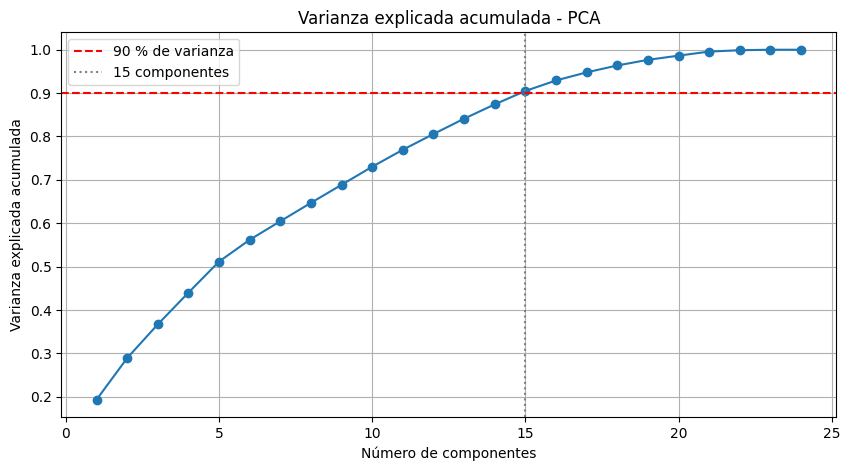

Variables numéricas iniciales: 24
Componentes necesarios (>= 90 %): 15
Varianza explicada: 90.49 %


In [ ]:
# ---------- ACTIVIDAD 5: CURVA DE VARIANZA ACUMULADA (PCA) ----------

# 1. Tomar solo las columnas numéricas del conjunto de ENTRENAMIENTO.
#    PCA solo funciona con números, no con texto.
X_train_num = X_train[columnas_numericas]

# 2. Rellenar los datos que faltan con la mediana (el valor del medio).
imputador_pca = SimpleImputer(strategy='median')             # Creo el "rellenador"
X_train_imputado = imputador_pca.fit_transform(X_train_num)  # Aprende las medianas y rellena

# 3. Poner todas las variables en la misma escala (media 0, desviación 1).
#    Sin esto, el peso (miles de gramos) pesaría más que la hora (0 a 23).
escalador_pca = StandardScaler()                                   # Creo el "escalador"
X_train_escalado = escalador_pca.fit_transform(X_train_imputado)   # Aprende y escala

# 4. Calcular TODAS las componentes principales (tantas como variables).
#    svd_solver='full' usa la descomposición en valores singulares (SVD) completa.
pca_completo = PCA(svd_solver='full')
pca_completo.fit(X_train_escalado)

# 5. Sumar la información que aporta cada componente, una tras otra.
#    explained_variance_ratio_ = cuánta información aporta cada componente.
#    cumsum = suma acumulada (1ª, 1ª+2ª, 1ª+2ª+3ª, ...).
varianza_acumulada = np.cumsum(pca_completo.explained_variance_ratio_)

# 6. Buscar cuántas componentes se necesitan para llegar al 90 %.
#    (varianza_acumulada >= 0.90) marca con True las que ya llegaron al 90 %.
#    argmax devuelve la posición del primer True; el +1 es porque Python cuenta desde 0.
n_componentes = int(np.argmax(varianza_acumulada >= 0.90) + 1)

# 7. Dibujar la gráfica.
plt.figure(figsize=(10, 5))                                    # Tamaño de la figura
plt.plot(range(1, len(varianza_acumulada) + 1),                # Eje X: 1, 2, 3, ... componentes
         varianza_acumulada, marker='o')                       # Eje Y: varianza acumulada
plt.axhline(y=0.90, color='red', linestyle='--',               # Línea roja horizontal en 90 %
            label='90 % de varianza')
plt.axvline(x=n_componentes, color='gray', linestyle=':',      # Línea gris vertical en el resultado
            label=f'{n_componentes} componentes')
plt.xlabel('Número de componentes')                            # Nombre del eje X
plt.ylabel('Varianza explicada acumulada')                     # Nombre del eje Y
plt.title('Varianza explicada acumulada - PCA')                # Título
plt.legend()                                                   # Leyenda
plt.grid()                                                     # Cuadrícula
plt.show()                                                     # Mostrar la gráfica

# 8. Imprimir las cifras que se deben informar.
print('Variables numéricas iniciales:', len(columnas_numericas))
print('Componentes necesarios (>= 90 %):', n_componentes)
print('Varianza explicada:', round(varianza_acumulada[n_componentes - 1] * 100, 2), '%')

## 10. Comparación de los cuatro modelos

### Actividad 6. Entrenar y comparar A, B, C y D
| Experimento | Transformación | Valor de C |
|---|---|---|
| A. Modelo de referencia | Variables numéricas sin PCA | 1,0 |
| B. Reducción de dimensión | PCA con 90 % de varianza | 1,0 |
| C. Mayor penalización | PCA con 90 % de varianza | 0,1 |
| D. Menor penalización | PCA con 90 % de varianza | 10,0 |

`C` controla la regularización de forma **inversa**: un valor menor significa una penalización más fuerte. Los cuatro modelos usan `class_weight='balanced'` y el umbral 0,50.

In [ ]:
# ---------- FUNCIÓN QUE CONSTRUYE CADA MODELO ----------
UMBRAL = 0.50    # Si la probabilidad de llegar tarde es >= 0,50, se clasifica como "tarde"
COSTO_FP = 8     # Costo didáctico de un falso positivo (R$)
COSTO_FN = 35    # Costo didáctico de un falso negativo (R$)

def construir_modelo(usar_pca, C):
    # Pasos para las columnas NUMÉRICAS: rellenar faltantes y escalar.
    pasos_num = [SimpleImputer(strategy='median'), StandardScaler()]
    if usar_pca:
        # Con un decimal, PCA conserva el mínimo de componentes que alcance ese % de varianza.
        pasos_num.append(PCA(n_components=0.90, svd_solver='full'))

    # Cada tipo de columna recibe su propio tratamiento.
    prep = ColumnTransformer([
        ('numericas', make_pipeline(*pasos_num), columnas_numericas),
        ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                      OneHotEncoder(handle_unknown='ignore')),
         columnas_categoricas)
    ])

    # Se encadena la preparación con la regresión logística.
    return make_pipeline(
        prep,
        LogisticRegression(C=C,                      # Fuerza de la regularización (inversa)
                           class_weight='balanced',  # Da más peso a la clase poco frecuente
                           max_iter=1000,            # Máximo de iteraciones
                           random_state=42)          # Semilla para reproducir resultados
    )

In [ ]:
# ---------- ENTRENAR LOS CUATRO EXPERIMENTOS Y MEDIRLOS EN VALIDACIÓN ----------
experimentos = {
    'A. Referencia (sin PCA, C=1.0)': dict(usar_pca=False, C=1.0),
    'B. PCA 90 %, C=1.0':             dict(usar_pca=True,  C=1.0),
    'C. PCA 90 %, C=0.1':             dict(usar_pca=True,  C=0.1),
    'D. PCA 90 %, C=10.0':            dict(usar_pca=True,  C=10.0),
}

modelos_s14 = {}   # Aquí se guardan los modelos ya entrenados
filas = []         # Aquí se guarda una fila de resultados por experimento

for nombre, cfg in experimentos.items():
    m = construir_modelo(**cfg)                    # Construye el modelo del experimento
    m.fit(X_train, y_train)                        # Entrena SOLO con entrenamiento
    modelos_s14[nombre] = m                        # Lo guarda

    proba_v = m.predict_proba(X_valid)[:, 1]       # Probabilidad de llegar tarde
    pred_v = (proba_v >= UMBRAL).astype(int)       # 1 si la probabilidad >= 0,50; si no, 0

    tn, fp, fn, tp = confusion_matrix(y_valid, pred_v).ravel()   # Aciertos y errores

    filas.append({
        'experimento': nombre,
        'accuracy': accuracy_score(y_valid, pred_v),                    # % de aciertos totales
        'precision': precision_score(y_valid, pred_v, zero_division=0), # De los "tarde" que dije, cuántos lo eran
        'recall': recall_score(y_valid, pred_v, zero_division=0),       # De los tardíos reales, cuántos detecté
        'f1': f1_score(y_valid, pred_v, zero_division=0),               # Balance entre precision y recall
        'average_precision': average_precision_score(y_valid, proba_v), # Calidad de las probabilidades
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),     # Matriz de confusión
        'costo_BRL': int(fp * COSTO_FP + fn * COSTO_FN),                # 8 por FP + 35 por FN
    })

resultados = pd.DataFrame(filas).set_index('experimento')
print('COMPARACIÓN EN VALIDACIÓN (umbral 0,50, class_weight="balanced")')
display(resultados.round(4))

COMPARACIÓN EN VALIDACIÓN (umbral 0,50, class_weight="balanced")


,accuracy,precision,recall,f1,average_precision,TN,FP,FN,TP,costo_BRL
experimento,,,,,,,,,,
"A. Referencia (sin PCA, C=1.0)",0.6695,0.1263,0.6545,0.2117,0.1508,3282,1612,123,233,17201
"B. PCA 90 %, C=1.0",0.6488,0.1157,0.6292,0.1955,0.1281,3182,1712,132,224,18316
"C. PCA 90 %, C=0.1",0.6518,0.1171,0.6320,0.1975,0.1284,3197,1697,131,225,18161
"D. PCA 90 %, C=10.0",0.6499,0.1165,0.6320,0.1967,0.1280,3187,1707,131,225,18241


In [ ]:
# ---------- COMPONENTES QUE CONSERVÓ CADA MODELO CON PCA ----------
for nombre in list(experimentos)[1:]:                       # B, C y D (A no usa PCA)
    pca_ajustado = (modelos_s14[nombre]
                    .named_steps['columntransformer']       # Paso de preparación
                    .named_transformers_['numericas']       # Parte numérica
                    .named_steps['pca'])                    # El PCA ya ajustado
    print(f'{nombre}: {pca_ajustado.n_components_} componentes, '
          f'{pca_ajustado.explained_variance_ratio_.sum() * 100:.2f} % de varianza')

B. PCA 90 %, C=1.0: 15 componentes, 90.49 % de varianza
C. PCA 90 %, C=0.1: 15 componentes, 90.49 % de varianza
D. PCA 90 %, C=10.0: 15 componentes, 90.49 % de varianza


### Actividad 7. Costo didáctico y elección del modelo
Con el supuesto de la semana 12 (R$ 8 por falso positivo y R$ 35 por falso negativo; **no son costos observados de Olist**) se calcula el costo de cada modelo en validación. La elección se hace con validación: el conjunto `test` no se toca.

Mayor Accuracy : A. Referencia (sin PCA, C=1.0)
Mayor Recall   : A. Referencia (sin PCA, C=1.0)
Menor costo    : A. Referencia (sin PCA, C=1.0) -> R$ 17201


,FP,FN,costo_BRL
experimento,,,
"A. Referencia (sin PCA, C=1.0)",1612,123,17201
"B. PCA 90 %, C=1.0",1712,132,18316
"C. PCA 90 %, C=0.1",1697,131,18161
"D. PCA 90 %, C=10.0",1707,131,18241


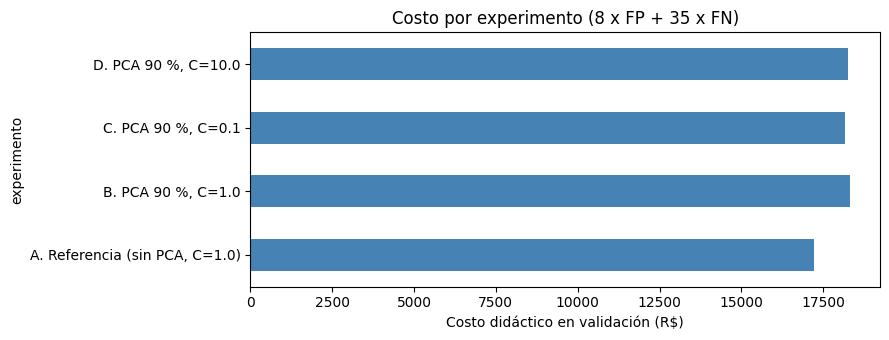

In [ ]:
# ---------- ACTIVIDAD 7: COSTO Y ELECCIÓN ----------
mejor_accuracy = resultados['accuracy'].idxmax()   # Modelo con más aciertos
mejor_recall = resultados['recall'].idxmax()       # Modelo que detecta más entregas tardías
mejor_costo = resultados['costo_BRL'].idxmin()     # Modelo con menor costo para la empresa

print('Mayor Accuracy :', mejor_accuracy)
print('Mayor Recall   :', mejor_recall)
print('Menor costo    :', mejor_costo,
      '-> R$', int(resultados.loc[mejor_costo, 'costo_BRL']))

# Detalle de errores y costo por modelo.
display(resultados[['FP', 'FN', 'costo_BRL']])

# Gráfica de barras con el costo de cada experimento.
ax = resultados['costo_BRL'].plot(kind='barh', figsize=(9, 3.5), color='steelblue')
ax.set_xlabel('Costo didáctico en validación (R$)')
ax.set_title('Costo por experimento (8 x FP + 35 x FN)')
plt.tight_layout()
plt.show()

## 11. Validación estadística: prueba de Kolmogorov-Smirnov

### Actividad 8. KS sobre `valor_flete` (entrenamiento frente a validación)
- **H₀:** `valor_flete` tiene la misma distribución en entrenamiento y validación.
- **H₁:** las distribuciones de `valor_flete` son diferentes.
- Nivel de significancia: 5 %.

In [ ]:
# ---------- ACTIVIDAD 8: PRUEBA KOLMOGOROV-SMIRNOV ----------
ALFA = 0.05   # Nivel de significancia (5 %)

# Compara la distribución de valor_flete en entrenamiento y en validación.
# dropna() quita los faltantes, porque la prueba no los acepta.
resultado_ks = ks_2samp(train['valor_flete'].dropna(),
                        valid['valor_flete'].dropna())

D = float(resultado_ks.statistic)    # Mayor diferencia entre las dos distribuciones acumuladas
p_valor = float(resultado_ks.pvalue) # Probabilidad de ver una diferencia así si H0 fuera cierta

print(f'Estadístico D = {D:.4f}')
print(f'Valor p       = {p_valor:.4f}')

# Regla de decisión: si p < 0,05 se rechaza H0.
if p_valor < ALFA:
    decision = 'Se rechaza H0 al 5 %'
else:
    decision = 'No se rechaza H0 al 5 %'
print('Decisión:', decision)

Estadístico D = 0.0103
Valor p       = 0.7402
Decisión: No se rechaza H0 al 5 %


## 12. Interpretación de la semana 14

**Pregunta de análisis:** ¿Es preferible el modelo que registra más aciertos, el que identifica más entregas tardías o el que representa un menor costo para la empresa? Sustente con sus resultados.

Escriba sus respuestas con los valores obtenidos en su propia muestra (ID 15).

1. **Curva de varianza acumulada.** Indique cuántas variables numéricas había, cuántas componentes se conservaron, qué información podría perderse y para qué sirve la reducción en este problema.

Respuesta: Se partió de 24 variables numéricas y, para conservar al menos el 90 % de la varianza, se necesitaron 15 componentes, que explican el 90,49 %. La reducción fue de 9 variables (37,5 %). La curva no tiene un codo marcado: la información está repartida entre muchas variables y no están tan relacionadas como para comprimirlas mucho. Al comprimir se descarta cerca del 9,5 % de la varianza, y las componentes son combinaciones de varias variables, por lo que son más difíciles de interpretar que las originales. En este problema la reducción sirve para resumir variables que varían juntas, como el valor de los productos, el precio máximo, el peso y el volumen, y para trabajar con menos dimensiones. Pero PCA no garantiza mejores predicciones, y aquí no las produjo, como se ve en la comparación de modelos.

2. **Comparación de las cuatro configuraciones.** Contraste el modelo sin PCA (A) con los modelos con PCA (B, C y D) usando Accuracy, Precision, Recall, F1 y Average Precision.

Respuesta: El modelo A (sin PCA) fue superior a B, C y D en las cinco métricas: Accuracy 0,6695 frente a 0,6488–0,6518, Precision 0,1263 frente a 0,1157–0,1171, Recall 0,6545 frente a 0,6292–0,6320, F1 0,2117 frente a 0,1955–0,1975 y Average Precision 0,1508 frente a cerca de 0,128. La mayor caída se dio en Average Precision, lo que indica que al comprimir las variables el modelo ordena peor los pedidos según su probabilidad de llegar tarde. Entre B, C y D las diferencias son mínimas: pasar de C=0,1 a C=10 casi no cambió las métricas, es decir, la regularización influyó poco comparada con aplicar o no PCA. La Precision es baja en los cuatro modelos (cerca de 0,12) porque solo cerca del 6,8 % de los pedidos son tardíos (356 de 5.250 en validación) y class_weight='balanced' genera muchos falsos positivos.

3. **Costo y decisión empresarial.** Indique falsos positivos, falsos negativos y costo de cada modelo, elija uno y justifique la decisión (recuerde que los costos son un supuesto didáctico).

Respuesta: Con el supuesto didáctico de R 8 por falso positivo y R$ 35 por falso negativo, los resultados en validación fueron: A con 1.612 FP, 123 FN y R 17.201; B con 1.712 FP, 132 FN y R 18.316; C con 1.697 FP, 131 FN y R 18.161; y D con 1.707 FP, 131 FN y R 18.241. En este caso el modelo A tiene más aciertos, identifica más entregas tardías (233 de 356 frente a 224–225) y es el de menor costo, por lo que no hay conflicto entre los tres criterios. Se elige el modelo A. Un falso negativo cuesta 4,4 veces más que un falso positivo, así que priorizar el Recall y el costo es coherente con el negocio, y A cuesta entre R 960 y R 1.115 menos que los modelos con PCA. Las cifras son un supuesto didáctico y no costos observados de Olist; además, la elección se hizo solo con validación y con el umbral fijo de 0,50, por lo que otro umbral podría cambiar el resultado.

4. **Prueba KS.** Formule las hipótesis, informe D, el valor p y la decisión al 5 %, y escriba una limitación metodológica.

Respuesta:Hipótesis: H₀: valor_flete tiene la misma distribución en entrenamiento y validación. H₁: las distribuciones de valor_flete son diferentes. Resultado: D = 0,0103 y valor p = 0,7402. Como p es mayor que 0,05, no se rechaza H₀ al 5 %: no hay evidencia de que la distribución del flete difiera entre las dos particiones, lo que sugiere que la separación fue razonable para esta variable. Limitación: no rechazar H₀ no demuestra que las distribuciones sean idénticas, solo que la muestra no dio evidencia de diferencia. Además, la prueba revisó una sola variable y no compara el desempeño de los modelos ni permite afirmar que una configuración sea estadísticamente superior a otra.

## Registro de resultados de la semana 14 ##
Se guardan en `reports/` el registro de experimentos (CSV y JSON) y un resumen. No se publican los archivos originales ni la muestra completa.

In [ ]:
# ---------- REGISTRO DE RESULTADOS S14 ----------
Path('reports').mkdir(parents=True, exist_ok=True)   # Crea la carpeta reports/ si no existe

# 1. Tabla de experimentos en CSV.
ruta_csv = Path(f'reports/S14_experimentos_ID_{identificador}.csv')
resultados.round(6).to_csv(ruta_csv)

# 2. Registro completo en JSON.
reporte14 = {
    'laboratorio': 'S14',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'huella_muestra': huella_muestra,
    'n_train': len(train), 'n_valid': len(valid), 'n_test': len(test),
    'umbral': UMBRAL,
    'class_weight': 'balanced',
    'costo_fp_brl': COSTO_FP, 'costo_fn_brl': COSTO_FN,
    'pca': {
        'variables_numericas_iniciales': len(columnas_numericas),
        'componentes_90pct': n_componentes,
        'varianza_explicada_pct': float(varianza_acumulada[n_componentes - 1] * 100),
    },
    'experimentos': json.loads(resultados.round(6).reset_index().to_json(orient='records')),
    'mejor_modelo_por_costo': mejor_costo,
    'ks_valor_flete': {'D': D, 'p_valor': p_valor, 'alfa': ALFA, 'decision': decision},
}
ruta_json = Path(f'reports/S14_resultados_ID_{identificador}.json')
ruta_json.write_text(json.dumps(reporte14, indent=2, ensure_ascii=False), encoding='utf-8')

# 3. Resumen del análisis (los textos entre paréntesis los redacta usted).
resumen = f"""# Resumen S14 - ID {identificador}

## PCA
- Variables numéricas iniciales: {len(columnas_numericas)}
- Componentes para >= 90 % de varianza: {n_componentes}
- Utilidad y posible pérdida de información: (escribir)

## Comparación de modelos (validación)
{resultados.round(4).to_string()}

- Modelo sin PCA frente a modelos con PCA: (escribir)
- Modelo elegido por menor costo: {mejor_costo}. Justificación empresarial: (escribir)

## Prueba KS sobre valor_flete
- Hipótesis: (escribir)
- D = {D:.4f}, p = {p_valor:.4f}, decisión: {decision}
- Limitación metodológica: (escribir)
"""
ruta_md = Path(f'reports/S14_resumen_ID_{identificador}.md')
ruta_md.write_text(resumen, encoding='utf-8')

print('Archivos generados:')
for ruta_s14 in (ruta_csv, ruta_json, ruta_md):
    print(' -', ruta_s14)

# En Colab, descarga los archivos para subirlos al repositorio.
try:
    from google.colab import files
    for ruta_s14 in (ruta_csv, ruta_json, ruta_md):
        files.download(str(ruta_s14))
except Exception:
    print('Si no se descargaron automáticamente, guárdelos manualmente desde reports/.')

Archivos generados:
 - reports/S14_experimentos_ID_15.csv
 - reports/S14_resultados_ID_15.json
 - reports/S14_resumen_ID_15.md


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>